In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
df=pd.read_csv("../data/cars.csv")

In [17]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='str')

In [18]:
df.shape

(15411, 14)

In [19]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [20]:
df.describe()

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


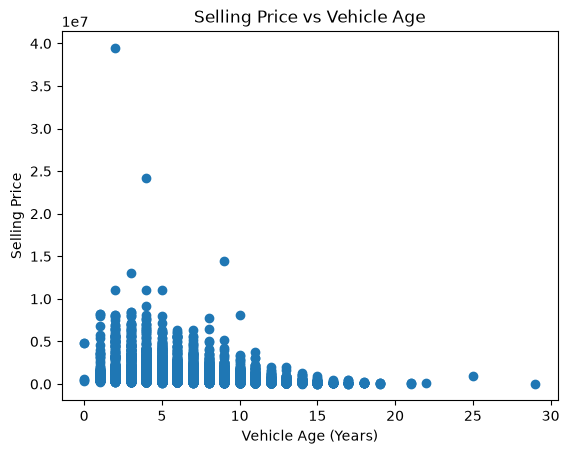

In [21]:
plt.scatter(df["vehicle_age"] , df["selling_price"])

plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Selling Price")
plt.title("Selling Price vs Vehicle Age")

plt.show()

In [22]:
df = df.drop(["Unnamed: 0", "car_name"], axis=1)

In [23]:
df.columns


Index(['brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='str')

In [24]:
X = df.drop("selling_price", axis=1)
y = df["selling_price"]

In [25]:
X = pd.get_dummies(X)

In [26]:
X.shape
X.head()

,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_Audi,brand_BMW,brand_Bentley,brand_Datsun,...,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,120000,19.70,796,46.30,5,False,False,False,False,...,False,True,False,False,False,False,False,True,False,True
1,5,20000,18.90,1197,82.00,5,False,False,False,False,...,False,True,False,False,False,False,False,True,False,True
2,11,60000,17.00,1197,80.00,5,False,False,False,False,...,False,True,False,False,False,False,False,True,False,True
3,9,37000,20.92,998,67.10,5,False,False,False,False,...,False,True,False,False,False,False,False,True,False,True
4,6,30000,22.77,1498,98.59,5,False,False,False,False,...,True,False,False,False,True,False,False,False,False,True


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [28]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

In [29]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

comparison.head()

,Actual,Predicted
0,190000,2.398000e+05
1,600000,6.271100e+05
2,665000,6.390400e+05
3,1570000,1.211750e+06
4,160000,1.797417e+05


In [30]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)

print(mae)

98940.1265122505


In [31]:
from sklearn.metrics import mean_squared_error
import math

mse = mean_squared_error(y_test, predictions)

rmse = math.sqrt(mse)

print(rmse)

214638.92300810342


In [32]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, predictions)

print(r2)

0.9388005025460214
